In [13]:
import numpy as np
import gmsh
import matplotlib.pyplot as plt

In [1]:
from Source.Pre_processing.Mesh import Mesh
from Source.core import Model
from Source.Material import material
from Source.Physics.FluidFlow import ff
from Source.Physics.Turbulence import sst, sa
from Source.enums import StudyType, ProblemType
from Source.logger_config import sim_logger

In [19]:
S = 0.0381 # Step height
hc = 0.0762 # Inlet channel height
H = 0.1143 # Outlet channel height
L1 = 0.3048 # Inlet channel length
L2 = 1.3335 # Outlet channel length

density = 1.225 # Fluid density
viscosity = 1.7894e-5 # Fluid viscosity
Re = 47625
Uav = Re * viscosity / (density * S) # Average velocity

In [3]:
Re = 36000.0
U_IN = 0.96                                                       # 1 at the edge of the layer at x = -4, which the walls accelerate
L, X, T = 100.0, 40.0, 9.0                                        # inlet at x = -L, outlet at x = X, top at y = T


In [4]:
lc = 0.1
lc_fine = 0.05


gmsh.initialize()
gmsh.option.setNumber("General.Terminal", 0)

In [5]:
scale = 1.0

In [7]:

gmsh.model.add('step')
g = gmsh.model.geo
nu = int(45 * scale); nd = int(90 * scale); nt = int(70 * scale); nb = int(30 * scale)
pts = {'a': (-L, 1), 'b': (0, 1), 'c': (X, 1), 'd': (-L, T), 'e': (0, T), 'f': (X, T), 'g': (0, 0), 'h': (X, 0)}
p = {k: g.addPoint(x, y, 0, 1.0) for k, (x, y) in pts.items()}
line = lambda a, b: g.addLine(p[a], p[b])
ab, bc, de, ef, ad, be, cf, gh, gb, hc = (line('a', 'b'), line('b', 'c'), line('d', 'e'), line('e', 'f'), line('a', 'd'),
                                            line('b', 'e'), line('c', 'f'), line('g', 'h'), line('g', 'b'), line('h', 'c'))
s1 = g.addPlaneSurface([g.addCurveLoop([ab, be, -de, -ad])])
s2 = g.addPlaneSurface([g.addCurveLoop([bc, cf, -ef, -be])])
s3 = g.addPlaneSurface([g.addCurveLoop([gh, hc, -bc, -gb])])
g.synchronize()
m = gmsh.model.mesh
m.setTransfiniteCurve(ab, nu + 1, 'Progression', 0.94)    # towards the step
m.setTransfiniteCurve(de, nu + 1, 'Progression', 0.94)
for c in (bc, ef, gh):
    m.setTransfiniteCurve(c, nd + 1, 'Progression', 1.03)  # away from the step
for c in (ad, be, cf):
    m.setTransfiniteCurve(c, nt + 1, 'Bump', 0.0013)       # to the floor and the top
for c in (gb, hc):
    m.setTransfiniteCurve(c, nb + 1, 'Bump', 0.006)        # to both ends
for s in (s1, s2, s3):
    m.setTransfiniteSurface(s)
    m.setRecombine(2, s)
gmsh.model.addPhysicalGroup(1, [ad], name='inlet')
gmsh.model.addPhysicalGroup(1, [cf, hc], name='outlet')
gmsh.model.addPhysicalGroup(1, [de, ef], name='top')
gmsh.model.addPhysicalGroup(1, [ab, gb, gh], name='floor')
gmsh.model.addPhysicalGroup(2, [s1, s2, s3], name='fluid')
m.generate(2)

In [8]:
import sys


if 'close' not in sys.argv:
    gmsh.fltk.run()

In [11]:
def mesh_step():
    gmsh.initialize()
    gmsh.option.setNumber("General.Terminal", 0)
    try:
        gmsh.model.add('step')
        g = gmsh.model.geo
        nu = int(45 * scale); nd = int(90 * scale); nt = int(70 * scale); nb = int(30 * scale)
        pts = {'a': (-L, 1), 'b': (0, 1), 'c': (X, 1), 'd': (-L, T), 'e': (0, T), 'f': (X, T), 'g': (0, 0), 'h': (X, 0)}
        p = {k: g.addPoint(x, y, 0, 1.0) for k, (x, y) in pts.items()}
        line = lambda a, b: g.addLine(p[a], p[b])
        ab, bc, de, ef, ad, be, cf, gh, gb, hc = (line('a', 'b'), line('b', 'c'), line('d', 'e'), line('e', 'f'), line('a', 'd'),
                                                  line('b', 'e'), line('c', 'f'), line('g', 'h'), line('g', 'b'), line('h', 'c'))
        s1 = g.addPlaneSurface([g.addCurveLoop([ab, be, -de, -ad])])
        s2 = g.addPlaneSurface([g.addCurveLoop([bc, cf, -ef, -be])])
        s3 = g.addPlaneSurface([g.addCurveLoop([gh, hc, -bc, -gb])])
        g.synchronize()
        m = gmsh.model.mesh
        m.setTransfiniteCurve(ab, nu + 1, 'Progression', 0.94)    # towards the step
        m.setTransfiniteCurve(de, nu + 1, 'Progression', 0.94)
        for c in (bc, ef, gh):
            m.setTransfiniteCurve(c, nd + 1, 'Progression', 1.03)  # away from the step
        for c in (ad, be, cf):
            m.setTransfiniteCurve(c, nt + 1, 'Bump', 0.0013)       # to the floor and the top
        for c in (gb, hc):
            m.setTransfiniteCurve(c, nb + 1, 'Bump', 0.006)        # to both ends
        for s in (s1, s2, s3):
            m.setTransfiniteSurface(s)
            m.setRecombine(2, s)
        gmsh.model.addPhysicalGroup(1, [ad], name='inlet')
        gmsh.model.addPhysicalGroup(1, [cf, hc], name='outlet')
        gmsh.model.addPhysicalGroup(1, [de, ef], name='top')
        gmsh.model.addPhysicalGroup(1, [ab, gb, gh], name='floor')
        gmsh.model.addPhysicalGroup(2, [s1, s2, s3], name='fluid')
        m.generate(2)
        m.setOrder(2)
        return Mesh.from_gmsh_model()
    finally:
        gmsh.finalize()

In [12]:
mesh = mesh_step()
xy = np.array([n.coor for n in mesh.NL])


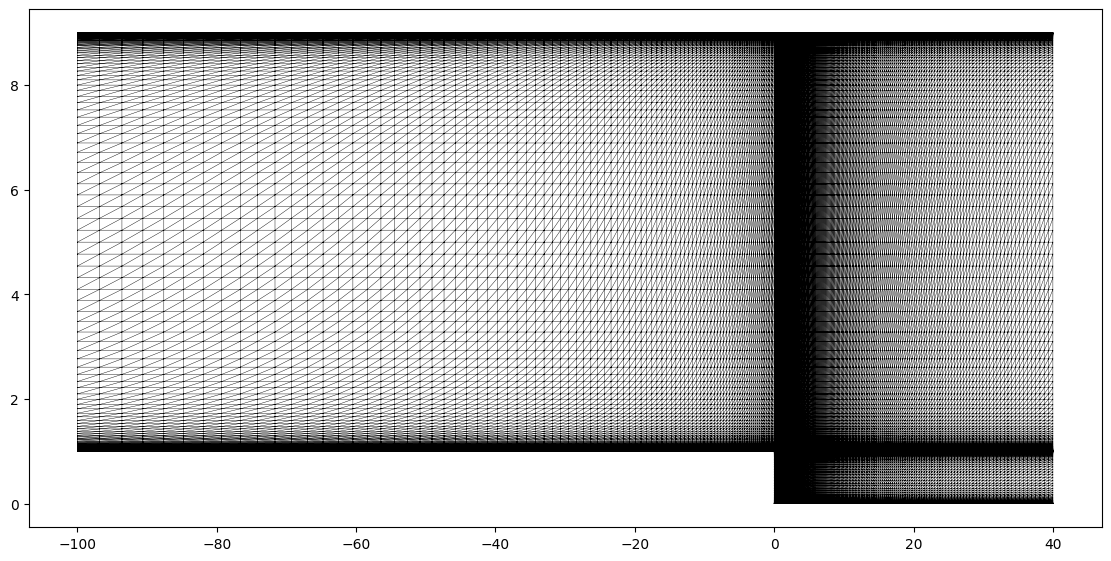

In [17]:
fig, axes = plt.subplots(1, 1, figsize=(11, 5.5), constrained_layout=True)

axes.triplot(mesh.triangulation(), lw=0.3, color='k')


plt.show()